# 1. Unit Search

The start of the meta progression: the algorithm of `../step_by_step/` on its deep sparse target network.
How does it compare with a fully connected network with network Autostep?

**Problem.** `problems.SparseTargetNetwork`. 1000 standard normal inputs. 3 hidden depths of 20 target LTUs, each
reading 10 units of lower depths. 100 outputs, each reading 10 target LTUs. Weights are N(0, 1), each target LTU fires
30% of the time, and each output has unit variance plus N(0, 1) noise.

**Algorithm.** `algorithms.UnitSearch`:

```
setup     3 depths of 40 LTU slots, each always holding an LTU. An LTU reads the inputs, the bias and LTUs of lower
          depth. The outputs read the inputs, every LTU and the bias. At step 0, each LTU is NEW and reads 20 random
          inputs.

every step
  LEARN   network Autostep. In the backward pass, each LTU's shadow (+1 or -1 on its parent) replaces its weight to
          its parent while that weight is smaller than 1 in size. G[u, j] += dL/dz_u * a_j, where
          a = [x, standardized LTU activations, 1] are the layer inputs.

every 1k steps
  GROW    each LTU u: j = the layer input with the largest |G[u, j]| among those that u may read but does not.
          If |G[u, j]| > 6 rms(G[u, unread]), u reads j (weight 0, step size 0.03), and G[u, :] = 0.

every 10k steps
  SWAP    for d = 3, 2: the depth-d LTU of highest utility with less than 10% of its input |weights| on depth d - 1
          changes depth with the depth-(d - 1) LTU of lowest utility, if that one has a lower utility. SEARCH
          replaces the LTU that moves up.
  SEARCH  replace the 1/8 of the LTUs with the lowest utility by NEW LTUs. The utility of an LTU is the sum of its
          |outgoing weights|.

NEW LTU u, from the top depth down
  parent p: a unit of a layer above u's depth (the outputs included), the layer and then the unit drawn uniformly.
  shadow(u -> p) = +1 in even slots and -1 in odd slots. If p is an LTU, p reads u from weight 0.
  u reads 20 layer inputs j drawn in proportion to w[p, j]^2, with LeCun uniform weights of sign shadow * w[p, j],
  at step size 0.03. Its output weights are 0.
```

**Baseline.** `algorithms.FullyConnected`: network Autostep on 3 hidden layers of 160 LTUs, each layer reading the one
below.

5 seeds, 1M steps.

**Result.** Unit search ends at RMSE 1.08, and the fully connected network at 1.12, where the noise std is 1.


In [1]:
import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
import jax
jax.config.update('jax_platforms', 'cuda')

from phd.sandbox.unit_search.algorithm import algorithms, experiment, problems

assert jax.default_backend() == 'gpu'
%matplotlib inline


/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
problem = problems.SparseTargetNetwork()
sizes = dict(n_inputs=problem.n_inputs, n_outputs=problem.n_outputs)
methods = {'fully connected, network Autostep (baseline)': algorithms.FullyConnected(**sizes),
           'unit search (proposed)': algorithms.UnitSearch(**sizes)}
rmse, _ = experiment.run(methods, problem, steps=1_000_000)


2026-11-22 21:52:49.083849: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-22 21:52:49.083917: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


fully connected, network Autostep (baseline): RMSE over the last 10% 1.122 (341s)


unit search (proposed): RMSE over the last 10% 1.079 (117s)


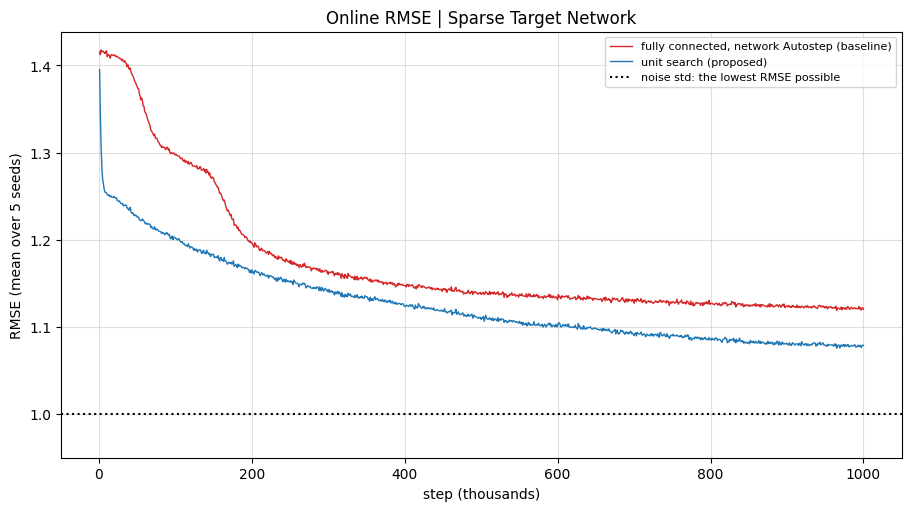

In [3]:
experiment.plot(rmse, problem, 'Online RMSE | Sparse Target Network')
